# CS-781 Capstone - Phase 1: Architecture 2 - Decoder-only Transformer with Multi-head Latent Attention (MLA)

**What it is:** same skeleton as Architecture 1, but attention is **Multi-head Latent Attention** (Assignment 3 Q2, DeepSeek-V2 style):
keys and values of all heads are rebuilt from ONE low-rank latent `c = norm(W_dkv x)` (rank 192). Because plain MLA has no place for RoPE, this version
uses the **decoupled-RoPE** design: a small rotary part (16 dims: per-head query + one shared key) next to the non-rotary 48-dim part.

| | |
|---|---|
| Attention | causal MLA, 12 heads, latent rank 192, q/k head dim 48+16, v dim 64 |
| Cache per token per layer | 192 + 16 = 208 numbers (MHA: 1536, GQA-4: 512) |
| Blocks | 16 x (RMSNorm -> MLA -> RMSNorm -> SwiGLU 2048) |
| Params | ~126M (attention params matched to Architecture 1) |
| Why it is in the set | different attention *parameterisation* (low-rank joint KV compression) at matched size and cache footprint trade-off |

**Downstream:** LoRA targets are `wq, w_dkv, w_ukv, wo` + SwiGLU (note that adapting `w_ukv` changes both K and V).

---
**How this notebook relates to the starter code.** Same pipeline and section order as the starter (HF login -> GPU -> config -> tokenizer -> data -> model -> train -> perplexity -> plot -> save -> generate 128 words -> `prediction.json` -> `submission.zip`),
with these replacements: (1) the GPT-2 tokenizer -> a **byte-level BPE tokenizer trained from scratch** on the provided corpus (lossless round trip, unlike the `Whitespace` pre-tokenizer used in Assignment 3);
(2) `GPT2LMHeadModel` + HF `Trainer` -> the architecture in `legal_arch.py` (written by the cell below) + a small custom training loop with resume support;
(3) `model.generate` -> KV-cache / state based generation that works for all architectures.

**Run order for the whole study:** run any one of the four architecture notebooks first - it downloads the data, trains the tokenizer and writes `cs781_phase1_data/` (`tokenizer.json`, `train.bin`, `val.bin`).
For the other three notebooks, attach the saved output of that first run as a Kaggle *input* (or copy the folder next to the notebook): they detect and reuse it, so all four models see the **same tokenizer, same data, same validation set**.

**Rules check:** trained from scratch, no pretrained weights, only the official data, 50M-300M params (asserted below).
Every hyper-parameter sits in the config cell - change one thing at a time and keep the printed logs for the report.

## 1. Hugging Face login

In [1]:
# Same as the starter: read the HF token from Kaggle secrets (secret name "HF"); falls back to env var / anonymous.
import os
HF_TOKEN = None
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
    from huggingface_hub import login
    login(token=HF_TOKEN)
    print("Hugging Face login successful.")
else:
    print("No HF token found - continuing anonymously (works only if the dataset is public).")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch
print("CUDA available:", torch.cuda.is_available())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i), "| capability", torch.cuda.get_device_capability(i))

CUDA available: True
GPU 0: Tesla T4 | capability (7, 5)
GPU 1: Tesla T4 | capability (7, 5)


## 3. Configuration

In [3]:
import os, sys, json, math, time, random, zipfile, shutil, glob, contextlib
from dataclasses import asdict
from pathlib import Path
import numpy as np
import torch

ARCH = "mla"                      # gqa | mla | encdec | retnet  (one notebook per architecture)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---------------- data (official HF dataset) ----------------
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_MIX = {                           # file -> share of the token budget (data-mixing knob, set a share to 0 to skip a file)
    "train_supreme_court.json": 0.50,
    "train_high_courts.json":   0.30,
    "train_tribunals.json":     0.10,
    "train_acts.json":          0.10,
}
TOTAL_TRAIN_TOKENS = 200_000_000        # prepared once, then reused by every architecture notebook
VAL_TOKENS         = 4_000_000          # validation = held-out DOCUMENTS (never seen in training)
VAL_DOC_PROB       = 0.02
NORMALIZE_WHITESPACE = True             # test prompts are plain 512-word strings: collapse newlines/runs of spaces
DELETE_DOWNLOADS   = True               # free disk after each file has been tokenized

# ---------------- tokenizer (byte-level BPE trained from scratch on the provided corpus) ----------------
VOCAB_SIZE       = 32_000
TOK_SAMPLE_CHARS = 200_000_000

# ---------------- model size overrides (defaults of ArchConfig give ~125M params) ----------------
CFG_OVERRIDES = {}

# ---------------- training ----------------
TRAIN_TOKENS     = TOTAL_TRAIN_TOKENS   # corpus tokens consumed (same budget for all 4 architectures => fair comparison)
MICRO_BATCH      = 4                    # lower this if you hit CUDA OOM (GRAD_ACCUM adapts automatically)
TOKENS_PER_STEP  = 65_536
LR, MIN_LR_RATIO = 5e-4, 0.1
WARMUP_STEPS     = 150
WEIGHT_DECAY     = 0.1
BETAS            = (0.9, 0.95)
GRAD_CLIP        = 1.0
LOG_EVERY        = 25
EVAL_EVERY       = 250
EVAL_BATCHES, EVAL_BS = 32, 8           # validation = 256 windows
EVAL_PREFIX, EVAL_CONT = 768, 512       # "continuation loss": NLL of 512 tokens given a 768-token prefix (same for all archs)
SAVE_EVERY       = 250
SNAP_FRACS       = [0.25, 0.5, 0.75, 1.0]   # model-only snapshots for checkpoint comparison
MAX_HOURS        = 11.0                 # safety stop (Kaggle session limit); checkpoint is saved, re-run the notebook to resume
RESUME           = True

# ---------------- generation ----------------
TARGET_WORDS = 128
MAX_NEW      = 400                      # token cap for the continuation
GEN_BS       = 16
DECODE = dict(temperature=0.2, top_p=0.9, top_k=0, rep_penalty=1.1)

# ---------------- paths ----------------
ROOT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
WORK = ROOT / f"cs781_phase1_{ARCH}"
DATA_DIR = ROOT / "cs781_phase1_data"
for d in (WORK, DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    AMP_DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16   # T4/P100 -> fp16
    torch.backends.cuda.matmul.allow_tf32 = True
else:
    AMP_DTYPE = None
def amp():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE) if device == "cuda" else contextlib.nullcontext()
print("device:", device, "| amp dtype:", AMP_DTYPE)

device: cuda | amp dtype: torch.float16


## 4. Tokenizer + data (byte-level BPE trained from scratch; skipped automatically when already prepared)

In [4]:
# If another architecture notebook (or a saved Kaggle output attached as input) already prepared the tokenizer + token
# files, reuse them: all four architectures must see the SAME tokenizer, data and validation set.
def find_prepared():
    cands = [DATA_DIR] + [Path(p).parent for p in glob.glob("/kaggle/input/**/meta.json", recursive=True)]
    for c in cands:
        if (c / "meta.json").exists() and (c / "tokenizer.json").exists() and (c / "train.bin").exists():
            return c
    return None

_found = find_prepared()
PREPARED = _found is not None
if PREPARED:
    DATA_DIR = _found
print("prepared data found:" , PREPARED, "->", DATA_DIR)

prepared data found: False -> /kaggle/working/cs781_phase1_data


In [5]:
# =================== data download + BPE tokenizer + tokenization (skipped if already prepared) ===================
if not PREPARED:
    try:
        import ijson
    except ImportError:
        os.system(f"{sys.executable} -m pip -q install ijson")
    from huggingface_hub import hf_hub_download, HfApi
    from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

    SPECIALS = ["<|endoftext|>", "<|pad|>", "<|bos|>"]            # ids 0, 1, 2
    EOS_ID, PAD_ID, BOS_ID = 0, 1, 2

    def norm(t):
        return " ".join(t.split()) if NORMALIZE_WHITESPACE else t

    def iter_docs(path):
        """Streams documents with ijson when available (RAM friendly), else json.load like the starter."""
        def text_of(r):
            return r if isinstance(r, str) else (r.get("text") or "")
        try:
            import ijson
        except ImportError:
            ijson = None
        if ijson is not None:
            with open(path, "rb") as f:
                first = f.read(1)
                while first and first.isspace():
                    first = f.read(1)
                f.seek(0)
                items = ijson.items(f, "item") if first == b"[" else (v for _, v in ijson.kvitems(f, ""))
                for r in items:
                    yield text_of(r)
        else:
            with open(path, encoding="utf-8") as f:
                data = json.load(f)
            for r in (data if isinstance(data, list) else list(data.values())):
                yield text_of(r)

    # ---- 1. download ----
    repo_files = HfApi().list_repo_files(HF_DATASET_REPO, repo_type="dataset", token=HF_TOKEN)
    paths = {}
    for name, share in TRAIN_MIX.items():
        if share <= 0:
            continue
        match = [f for f in repo_files if f.endswith("/" + name) and "Phase_1" in f]
        assert match, f"{name} not found in the dataset repo. Files: {repo_files[:30]}"
        paths[name] = hf_hub_download(HF_DATASET_REPO, match[0], repo_type="dataset", token=HF_TOKEN)
        print("downloaded", name, f"{os.path.getsize(paths[name]) / 1e9:.2f} GB")

    # ---- 2. byte-level BPE tokenizer, trained from scratch on a sample of the provided corpus ----
    def tok_iter():
        for name, share in TRAIN_MIX.items():
            if share <= 0:
                continue
            quota, got = int(TOK_SAMPLE_CHARS * share), 0
            for t in iter_docs(paths[name]):
                t = norm(t)
                if len(t) < 200:
                    continue
                t = t[:100_000]
                yield t
                got += len(t)
                if got >= quota:
                    break

    tok = Tokenizer(models.BPE())
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIALS, min_frequency=2,
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=True)
    tok.train_from_iterator(tok_iter(), trainer=trainer)
    tok.save(str(DATA_DIR / "tokenizer.json"))
    print("tokenizer vocab size:", tok.get_vocab_size())

    # ---- 3. tokenize into uint16 token files (documents separated by <|endoftext|>) ----
    rng = random.Random(SEED)

    def tokenize_source(path, btr, bva, ftr, fva):
        ntr = nva = 0
        buf = []
        def flush():
            nonlocal ntr, nva
            if not buf:
                return
            for (is_val, _), e in zip(buf, tok.encode_batch([t for _, t in buf])):
                ids = np.asarray(e.ids + [EOS_ID], dtype=np.uint16)
                if is_val:
                    ids.tofile(fva); nva += len(ids)
                else:
                    ids.tofile(ftr); ntr += len(ids)
            buf.clear()
        for t in iter_docs(path):
            t = norm(t)
            if len(t) < 200:
                continue
            is_val = rng.random() < VAL_DOC_PROB          # document-level split => no leakage
            if is_val and nva >= bva:
                continue
            if not is_val and ntr >= btr:
                if nva >= bva:
                    break
                continue
            buf.append((is_val, t))
            if len(buf) >= 256:
                flush()
        flush()
        return ntr, nva

    stats = {}
    with open(DATA_DIR / "train.bin", "wb") as ftr, open(DATA_DIR / "val.bin", "wb") as fva:
        for name, share in TRAIN_MIX.items():
            if share <= 0:
                continue
            t0 = time.time()
            ntr, nva = tokenize_source(paths[name], int(TOTAL_TRAIN_TOKENS * share), int(VAL_TOKENS * share), ftr, fva)
            stats[name] = {"train_tokens": ntr, "val_tokens": nva}
            print(f"{name}: train {ntr:,} | val {nva:,} tokens  ({time.time() - t0:.0f}s)")
            if DELETE_DOWNLOADS:
                try:
                    os.remove(os.path.realpath(paths[name])); os.remove(paths[name])
                except OSError:
                    pass
    json.dump({"vocab_size": tok.get_vocab_size(), "eos_id": EOS_ID, "pad_id": PAD_ID, "bos_id": BOS_ID,
               "normalize_whitespace": NORMALIZE_WHITESPACE, "sources": stats, "mix": TRAIN_MIX},
              open(DATA_DIR / "meta.json", "w"), indent=2)
    PREPARED = True
    print("Prepared data written to", DATA_DIR)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 4.0 MB/s eta 0:00:00


Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

downloaded train_supreme_court.json 1.32 GB


Phase_1_Pretraining/Train/train_high_cou(…):   0%|          | 0.00/10.7G [00:00<?, ?B/s]

downloaded train_high_courts.json 10.67 GB


Phase_1_Pretraining/Train/train_tribunal(…):   0%|          | 0.00/6.48G [00:00<?, ?B/s]

downloaded train_tribunals.json 6.48 GB


Phase_1_Pretraining/Train/train_acts.jso(…):   0%|          | 0.00/729M [00:00<?, ?B/s]

downloaded train_acts.json 0.73 GB



tokenizer vocab size: 32000
train_supreme_court.json: train 100,574,745 | val 3,055,621 tokens  (143s)
train_high_courts.json: train 60,023,102 | val 1,315,102 tokens  (74s)
train_tribunals.json: train 20,214,108 | val 424,477 tokens  (29s)
train_acts.json: train 20,448,945 | val 2,215,551 tokens  (42s)
Prepared data written to /kaggle/working/cs781_phase1_data


In [6]:
from tokenizers import Tokenizer
tokenizer = Tokenizer.from_file(str(DATA_DIR / "tokenizer.json"))
META = json.load(open(DATA_DIR / "meta.json"))
VOCAB = tokenizer.get_vocab_size()
EOS_ID, PAD_ID, BOS_ID = META["eos_id"], META["pad_id"], META["bos_id"]
NORMALIZE_WHITESPACE = META["normalize_whitespace"]
def norm(t):
    return " ".join(t.split()) if NORMALIZE_WHITESPACE else t

train_mm = np.memmap(DATA_DIR / "train.bin", dtype=np.uint16, mode="r")
val_mm   = np.memmap(DATA_DIR / "val.bin",   dtype=np.uint16, mode="r")
print(f"vocab {VOCAB} | train tokens {len(train_mm):,} | val tokens {len(val_mm):,}")

# tokenizer efficiency (report material): tokens per word on the validation text
_sample = tokenizer.decode(val_mm[:200_000].astype(np.int64).tolist())
print(f"tokens/word on val sample: {200_000 / max(1, len(_sample.split())):.3f}")

# test prompts (official)
from huggingface_hub import hf_hub_download, HfApi
_files = HfApi().list_repo_files(HF_DATASET_REPO, repo_type="dataset", token=HF_TOKEN)
_test = [f for f in _files if "Phase_1_Pretraining/Test/" in f and f.endswith(".json")]
print("test file candidates:", _test)
test_file_path = hf_hub_download(HF_DATASET_REPO, _test[0], repo_type="dataset", token=HF_TOKEN)
test_data = json.load(open(test_file_path, encoding="utf-8"))
print("Number of test examples:", len(test_data))
_lens = [len(tokenizer.encode(norm(v["text"])).ids) for v in list(test_data.values())[:200]]
print(f"test prompt tokens: mean {np.mean(_lens):.0f} | max {max(_lens)}")

vocab 32000 | train tokens 201,260,900 | val tokens 7,010,751
tokens/word on val sample: 1.220
test file candidates: ['Phase_1_Pretraining/Test/test.json']


test.json: 0.00B [00:00, ?B/s]

Number of test examples: 1000
test prompt tokens: mean 606 | max 925


## 5. Define the model
The next cell writes `legal_arch.py` (shared layers + this architecture). Keep this file - Phases 2-7 import it.

In [7]:
%%writefile legal_arch.py
import math, random
from dataclasses import dataclass, asdict
import torch
import torch.nn as nn
import torch.nn.functional as F


# ------------------------------------------------------------------ shared layers
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):
        dt = x.dtype
        x = x.float()
        x = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return (x * self.weight.float()).to(dt)


class SwiGLU(nn.Module):
    def __init__(self, d, d_ff):
        super().__init__()
        self.w_gate = nn.Linear(d, d_ff, bias=False)
        self.w_up = nn.Linear(d, d_ff, bias=False)
        self.w_down = nn.Linear(d_ff, d, bias=False)

    def forward(self, x):
        return self.w_down(F.silu(self.w_gate(x)) * self.w_up(x))


# RoPE: same split-half "rotate_half" convention as Assignment 3 (rope.py)
def build_rope_cache(max_len, dim, base=10000.0):
    assert dim % 2 == 0
    inv_freq = 1.0 / (base ** (torch.arange(0, dim // 2, dtype=torch.float32) * 2.0 / dim))
    freqs = torch.outer(torch.arange(max_len, dtype=torch.float32), inv_freq)
    ang = torch.cat([freqs, freqs], dim=-1)
    return ang.cos(), ang.sin()


def rotate_half(x):
    h = x.shape[-1] // 2
    return torch.cat([-x[..., h:], x[..., :h]], dim=-1)


def apply_rope(x, cos, sin):
    # x: (..., T, dim); cos/sin: (T, dim). Computed in fp32, returned in x.dtype
    xf = x.float()
    return (xf * cos + rotate_half(xf) * sin).to(x.dtype)


def init_weights(model, n_layers, std=0.02):
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=std)
    for name, p in model.named_parameters():
        if name.endswith("wo.weight") or name.endswith("w_down.weight"):
            nn.init.normal_(p, mean=0.0, std=std / math.sqrt(2 * n_layers))


# ------------------------------------------------------------------ decoder-only skeleton
# Used by GQA, MLA and Retention models: they only differ in the "attn" module plugged in.
# Every attn module has the signature  attn(x, cos, sin, cache=None)  where `cache` is a
# per-layer dict that the module fills/extends (this gives fast incremental generation).
class DecoderBlock(nn.Module):
    def __init__(self, d, d_ff, attn):
        super().__init__()
        self.norm1 = RMSNorm(d)
        self.attn = attn
        self.norm2 = RMSNorm(d)
        self.ffn = SwiGLU(d, d_ff)

    def forward(self, x, cos, sin, cache=None):
        x = x + self.attn(self.norm1(x), cos, sin, cache)
        return x + self.ffn(self.norm2(x))


class DecoderLM(nn.Module):
    kind = "decoder"

    def __init__(self, cfg, attn_factory, rope_dim):
        super().__init__()
        self.cfg = cfg
        self.block_len = cfg.max_seq_len + 1          # training window (x = w[:-1], y = w[1:])
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.blocks = nn.ModuleList(
            [DecoderBlock(cfg.d_model, cfg.d_ff, attn_factory(i)) for i in range(cfg.n_layers)])
        self.norm_f = RMSNorm(cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight     # tied embeddings
        cos, sin = build_rope_cache(cfg.max_seq_len, rope_dim)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)
        init_weights(self, cfg.n_layers)

    def max_prompt(self, max_new):
        return self.cfg.max_seq_len - max_new

    def hidden(self, idx, caches=None):
        x = self.tok_emb(idx)
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope_cos, self.rope_sin, None if caches is None else caches[i])
        return self.norm_f(x)

    def forward(self, idx):
        return self.lm_head(self.hidden(idx))

    def training_loss(self, batch):
        logits = self(batch[:, :-1])
        return F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), batch[:, 1:].reshape(-1))

    @torch.no_grad()
    def eval_continuation_loss(self, batch, e):
        """NLL of tokens batch[:, e:] given batch[:, :e] (comparable across ALL architectures).
        Returns (sum_nll_continuation, n_continuation, sum_nll_all_positions, n_all)."""
        logits = self(batch[:, :-1]).float()
        y = batch[:, 1:]
        nll = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1),
                              reduction="none").view(y.shape)
        cont = nll[:, e - 1:]
        return cont.sum().item(), cont.numel(), nll.sum().item(), nll.numel()

    @torch.no_grad()
    def prefill(self, prompt_ids):
        caches = [dict() for _ in self.blocks]
        h = self.hidden(prompt_ids, caches)
        return self.lm_head(h[:, -1]), caches

    @torch.no_grad()
    def decode_step(self, next_ids, caches):
        h = self.hidden(next_ids[:, None], caches)
        return self.lm_head(h[:, -1]), caches

# ============================================================ ARCH 2: Multi-head Latent Attention decoder
ARCH_NAME = "mla"


@dataclass
class ArchConfig:
    vocab_size: int
    d_model: int = 768
    n_layers: int = 16
    n_heads: int = 12
    kv_rank: int = 192           # size of the shared KV latent (this is what would be cached)
    d_nope: int = 48             # per-head query/key dims WITHOUT rotary
    d_rope: int = 16             # per-head query dims / shared key dims WITH rotary (decoupled RoPE)
    d_v: int = 64                # per-head value dim (= d_nope + d_rope so q,k,v share one head dim)
    d_ff: int = 2048
    max_seq_len: int = 2048
    dropout: float = 0.0


class MLAttention(nn.Module):
    """DeepSeek-V2-style MLA: K and V are rebuilt from one low-rank latent c = norm(W_dkv x).
    Position information goes through a small decoupled RoPE part (q_rope per head, one shared k_rope).
    Extends the simplified MLA of Assignment 3 (Q2.1) with decoupled RoPE so it can be used with rotary positions."""

    def __init__(self, d, n_heads, kv_rank, d_nope, d_rope, d_v, dropout=0.0):
        super().__init__()
        assert d_nope + d_rope == d_v, "keep q/k/v head dims equal so SDPA kernels stay happy"
        self.nh, self.r, self.dn, self.dr, self.dv = n_heads, kv_rank, d_nope, d_rope, d_v
        self.dropout = dropout
        self.wq = nn.Linear(d, n_heads * (d_nope + d_rope), bias=False)
        self.w_dkv = nn.Linear(d, kv_rank + d_rope, bias=False)      # latent + shared rotary key
        self.kv_norm = RMSNorm(kv_rank)
        self.w_ukv = nn.Linear(kv_rank, n_heads * (d_nope + d_v), bias=False)
        self.wo = nn.Linear(n_heads * d_v, d, bias=False)

    def forward(self, x, cos, sin, cache=None):
        B, T, _ = x.shape
        nh, dn, dr, dv, r = self.nh, self.dn, self.dr, self.dv, self.r
        q = self.wq(x).view(B, T, nh, dn + dr).transpose(1, 2)
        q_nope, q_rope = q[..., :dn], q[..., dn:]
        ckv = self.w_dkv(x)
        c = self.kv_norm(ckv[..., :r])                     # (B, T, r)
        kr = ckv[..., r:].unsqueeze(1)                     # (B, 1, T, dr)  shared across heads
        p0 = cache["c"].shape[1] if (cache is not None and "c" in cache) else 0
        q_rope = apply_rope(q_rope, cos[p0:p0 + T], sin[p0:p0 + T])
        kr = apply_rope(kr, cos[p0:p0 + T], sin[p0:p0 + T])
        if cache is not None:
            if "c" in cache:
                c = torch.cat([cache["c"], c], dim=1)
                kr = torch.cat([cache["kr"], kr], dim=2)
            cache["c"], cache["kr"] = c, kr                # cache = latent (r) + rope key (dr) per token
        S = c.shape[1]
        kv = self.w_ukv(c).view(B, S, nh, dn + dv).transpose(1, 2)
        k_nope, v = kv[..., :dn], kv[..., dn:]
        k = torch.cat([k_nope, kr.expand(B, nh, S, dr)], dim=-1)
        q = torch.cat([q_nope, q_rope], dim=-1)
        o = F.scaled_dot_product_attention(
            q, k, v, dropout_p=self.dropout if self.training else 0.0, is_causal=(T == S and T > 1))
        return self.wo(o.transpose(1, 2).reshape(B, T, nh * dv))


def build_model(cfg):
    return DecoderLM(
        cfg, lambda i: MLAttention(cfg.d_model, cfg.n_heads, cfg.kv_rank, cfg.d_nope, cfg.d_rope,
                                   cfg.d_v, cfg.dropout),
        rope_dim=cfg.d_rope)

Writing legal_arch.py


In [8]:
import importlib
import legal_arch as LA
importlib.reload(LA)

# Quick self-test on a TINY copy of the architecture (seconds, CPU). Verifies the things that silently ruin pre-training:
# causality / bidirectionality, and that incremental generation (KV-cache / retention state) equals the full forward pass.
TINY = dict(d_model=64, n_layers=2, n_heads=4, kv_rank=16, d_nope=12, d_rope=4, d_v=16, d_ff=128, max_seq_len=64)
def sanity_check():
    torch.manual_seed(0)
    m = LA.build_model(LA.ArchConfig(vocab_size=101, **TINY)).eval()
    close = lambda a, b: torch.allclose(a, b, atol=1e-3, rtol=1e-3)
    with torch.no_grad():
        if m.kind == "decoder":
            idx = torch.randint(3, 101, (2, 40))
            full = m(idx)
            idx2 = idx.clone(); idx2[:, 25:] = torch.randint(3, 101, (2, 15))
            assert close(full[:, :25], m(idx2)[:, :25]), "causality violated"
            lg, cache = m.prefill(idx[:, :30])
            assert close(lg, full[:, 29]), "prefill != full forward"
            for t in range(30, 40):
                lg, cache = m.decode_step(idx[:, t], cache)
                assert close(lg, full[:, t]), f"incremental decode differs at {t}"
            if LA.ARCH_NAME == "retnet":
                for blk in m.blocks:
                    blk.attn.chunk = 64                 # one chunk instead of several
                assert close(full, m(idx)), "chunkwise retention is not chunk-size invariant"
        else:
            enc = torch.randint(3, 101, (2, 24)); d = torch.randint(3, 101, (2, 12))
            bos = torch.full((2, 1), m.cfg.bos_id)
            eo = m.encode(enc)
            full = m.decode(torch.cat([bos, d], 1), eo)
            enc2 = enc.clone(); enc2[:, -1] = (enc2[:, -1] - 2) % 98 + 3
            assert not close(m.encode(enc2)[:, 0], eo[:, 0]), "encoder should be bidirectional"
            lg, cache = m.prefill(enc)
            assert close(lg, full[:, 0]), "prefill != full forward"
            for t in range(12):
                lg, cache = m.decode_step(d[:, t], cache)
                assert close(lg, full[:, t + 1]), f"incremental decode differs at {t}"
    print("sanity checks passed for", LA.ARCH_NAME)
sanity_check()

sanity checks passed for mla


In [9]:
import importlib
import legal_arch as LA
importlib.reload(LA)

cfg = LA.ArchConfig(vocab_size=VOCAB, **CFG_OVERRIDES)
model = LA.build_model(cfg).to(device)
n_params = sum(p.numel() for p in model.parameters())
n_emb = model.tok_emb.weight.numel()
print(f"[{LA.ARCH_NAME}] parameters: {n_params / 1e6:.2f}M  (embeddings {n_emb / 1e6:.2f}M, rest {(n_params - n_emb) / 1e6:.2f}M)")
assert 50e6 <= n_params <= 300e6, "Phase-1 rule: 50M - 300M parameters"
print(cfg)

[mla] parameters: 125.66M  (embeddings 24.58M, rest 101.08M)
ArchConfig(vocab_size=32000, d_model=768, n_layers=16, n_heads=12, kv_rank=192, d_nope=48, d_rope=16, d_v=64, d_ff=2048, max_seq_len=2048, dropout=0.0)


## 6. Training (custom loop: fp16/bf16 autocast, cosine schedule, checkpoint + resume, val every N steps)

In [10]:
BLOCK = model.block_len
GRAD_ACCUM  = max(1, round(TOKENS_PER_STEP / (MICRO_BATCH * BLOCK)))
TOTAL_STEPS = max(1, TRAIN_TOKENS // (MICRO_BATCH * GRAD_ACCUM * BLOCK))
print(f"block {BLOCK} | micro-batch {MICRO_BATCH} x accum {GRAD_ACCUM} | {MICRO_BATCH * GRAD_ACCUM * BLOCK:,} tokens/step | {TOTAL_STEPS} steps")

# ---- data: every block is seen once per epoch (deterministic permutation => resumable) ----
n_blocks = len(train_mm) // BLOCK
_perm = {}
def block_index(n):
    ep, pos = divmod(n, n_blocks)
    if ep not in _perm:
        _perm.clear()
        _perm[ep] = np.random.default_rng(SEED + ep).permutation(n_blocks)
    return _perm[ep][pos]

def get_train_batch(micro_idx):
    rows = [np.asarray(train_mm[b * BLOCK:(b + 1) * BLOCK]) for b in
            (block_index(micro_idx * MICRO_BATCH + i) for i in range(MICRO_BATCH))]
    return torch.from_numpy(np.stack(rows).astype(np.int64)).to(device)

EVAL_W = EVAL_PREFIX + EVAL_CONT
n_val_w = len(val_mm) // EVAL_W

@torch.no_grad()
def evaluate():
    """Returns (continuation_loss, all_position_loss). continuation_loss is identical in definition for every architecture."""
    model.eval()
    sc = sn = sa = na = 0.0
    for i in range(0, min(EVAL_BATCHES * EVAL_BS, n_val_w), EVAL_BS):
        rows = [np.asarray(val_mm[j * EVAL_W:(j + 1) * EVAL_W]) for j in range(i, min(i + EVAL_BS, n_val_w))]
        b = torch.from_numpy(np.stack(rows).astype(np.int64)).to(device)
        with amp():
            a1, a2, a3, a4 = model.eval_continuation_loss(b, EVAL_PREFIX)
        sc += a1; sn += a2; sa += a3; na += a4
    model.train()
    return sc / sn, sa / na

# ---- optimiser / schedule ----
decay = [p for n, p in model.named_parameters() if p.ndim >= 2 and "tok_emb" not in n]
no_decay = [p for n, p in model.named_parameters() if not (p.ndim >= 2 and "tok_emb" not in n)]
opt = torch.optim.AdamW([{"params": decay, "weight_decay": WEIGHT_DECAY}, {"params": no_decay, "weight_decay": 0.0}],
                        lr=LR, betas=BETAS, fused=(device == "cuda"))
try:
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda" and AMP_DTYPE == torch.float16))
except AttributeError:
    scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and AMP_DTYPE == torch.float16))

def get_lr(step):
    if step < WARMUP_STEPS:
        return LR * (step + 1) / WARMUP_STEPS
    prog = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
    return LR * (MIN_LR_RATIO + (1 - MIN_LR_RATIO) * 0.5 * (1 + math.cos(math.pi * prog)))

def atomic_save(obj, path):
    tmp = str(path) + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)

def half_state(m):
    return {k: (v.half() if v.is_floating_point() else v) for k, v in m.state_dict().items()}

CKPT_LAST, CKPT_BEST = WORK / "ckpt_last.pt", WORK / "ckpt_best.pt"
SNAP_STEPS = {max(1, int(TOTAL_STEPS * f)) for f in SNAP_FRACS}
history, train_log, best_val, start_step = [], [], float("inf"), 0

if RESUME:                                                  # look in working dir and in attached Kaggle inputs
    _ck = [CKPT_LAST] + [Path(p) for p in glob.glob(f"/kaggle/input/**/cs781_phase1_{ARCH}/ckpt_last.pt", recursive=True)]
    _ck = [p for p in _ck if p.exists()]
    if _ck:
        ck = torch.load(_ck[0], map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        start_step, history, train_log, best_val = ck["step"], ck["history"], ck["train_log"], ck["best_val"]
        print(f"resumed from {_ck[0]} at step {start_step}")

t_start, t_log, tok_log = time.time(), time.time(), 0
model.train()
for step in range(start_step, TOTAL_STEPS):
    for g in opt.param_groups:
        g["lr"] = get_lr(step)
    loss_acc = 0.0
    for m in range(GRAD_ACCUM):
        batch = get_train_batch(step * GRAD_ACCUM + m)
        with amp():
            loss = model.training_loss(batch)
        scaler.scale(loss / GRAD_ACCUM).backward()
        loss_acc += loss.item() / GRAD_ACCUM
    scaler.unscale_(opt)
    gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    if not math.isfinite(loss_acc):
        raise RuntimeError("Loss is NaN/inf - lower LR or check fp16 overflow.")
    s = step + 1
    tok_log += MICRO_BATCH * GRAD_ACCUM * BLOCK
    train_log.append((s, loss_acc))
    if s % LOG_EVERY == 0:
        dt = time.time() - t_log
        el = time.time() - t_start
        print(f"step {s}/{TOTAL_STEPS} | loss {loss_acc:.3f} | lr {get_lr(step):.2e} | gnorm {float(gnorm):.2f} | "
              f"{tok_log / dt:,.0f} tok/s | {el / 3600:.2f}h | ETA {(TOTAL_STEPS - s) * el / max(1, s - start_step) / 3600:.2f}h")
        t_log, tok_log = time.time(), 0
    if s % EVAL_EVERY == 0 or s == TOTAL_STEPS:
        v_cont, v_all = evaluate()
        history.append({"step": s, "tokens": s * MICRO_BATCH * GRAD_ACCUM * BLOCK, "train_loss": loss_acc,
                        "val_cont_loss": v_cont, "val_cont_ppl": math.exp(v_cont), "val_all_loss": v_all})
        print(f"  >> step {s}: val continuation loss {v_cont:.4f} (ppl {math.exp(v_cont):.2f}) | val all-position loss {v_all:.4f}")
        if v_cont < best_val:
            best_val = v_cont
            atomic_save({"model": half_state(model), "step": s, "val_cont_loss": v_cont}, CKPT_BEST)
    if s in SNAP_STEPS:
        atomic_save({"model": half_state(model), "step": s}, WORK / f"snap_step{s}.pt")
    out_of_time = (time.time() - t_start) / 3600 > MAX_HOURS
    if s % SAVE_EVERY == 0 or s == TOTAL_STEPS or out_of_time:
        atomic_save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(), "step": s,
                     "history": history, "train_log": train_log, "best_val": best_val}, CKPT_LAST)
    if out_of_time:
        print("MAX_HOURS reached - checkpoint saved. Re-run the notebook to resume.")
        break
json.dump({"history": history, "train_log": train_log, "params": n_params, "arch": ARCH}, open(WORK / "train_log.json", "w"))
print("training finished. best val continuation loss:", best_val)

block 2049 | micro-batch 4 x accum 8 | 65,568 tokens/step | 3050 steps
step 25/3050 | loss 7.314 | lr 8.33e-05 | gnorm 2.99 | 10,444 tok/s | 0.04h | ETA 5.28h
step 50/3050 | loss 5.804 | lr 1.67e-04 | gnorm 1.51 | 10,139 tok/s | 0.09h | ETA 5.31h
step 75/3050 | loss 5.197 | lr 2.50e-04 | gnorm 1.03 | 10,162 tok/s | 0.13h | ETA 5.29h
step 100/3050 | loss 4.925 | lr 3.33e-04 | gnorm 0.87 | 10,155 tok/s | 0.18h | ETA 5.26h
step 125/3050 | loss 4.667 | lr 4.17e-04 | gnorm 1.24 | 10,158 tok/s | 0.22h | ETA 5.22h
step 150/3050 | loss 4.460 | lr 5.00e-04 | gnorm 1.03 | 10,163 tok/s | 0.27h | ETA 5.18h
step 175/3050 | loss 4.206 | lr 5.00e-04 | gnorm 0.74 | 10,110 tok/s | 0.31h | ETA 5.14h
step 200/3050 | loss 4.086 | lr 5.00e-04 | gnorm 0.83 | 10,172 tok/s | 0.36h | ETA 5.10h
step 225/3050 | loss 3.798 | lr 4.99e-04 | gnorm 0.81 | 10,162 tok/s | 0.40h | ETA 5.05h
step 250/3050 | loss 4.055 | lr 4.99e-04 | gnorm 0.75 | 10,161 tok/s | 0.45h | ETA 5.01h
  >> step 250: val continuation loss 4.399

## 7. Training / validation curves

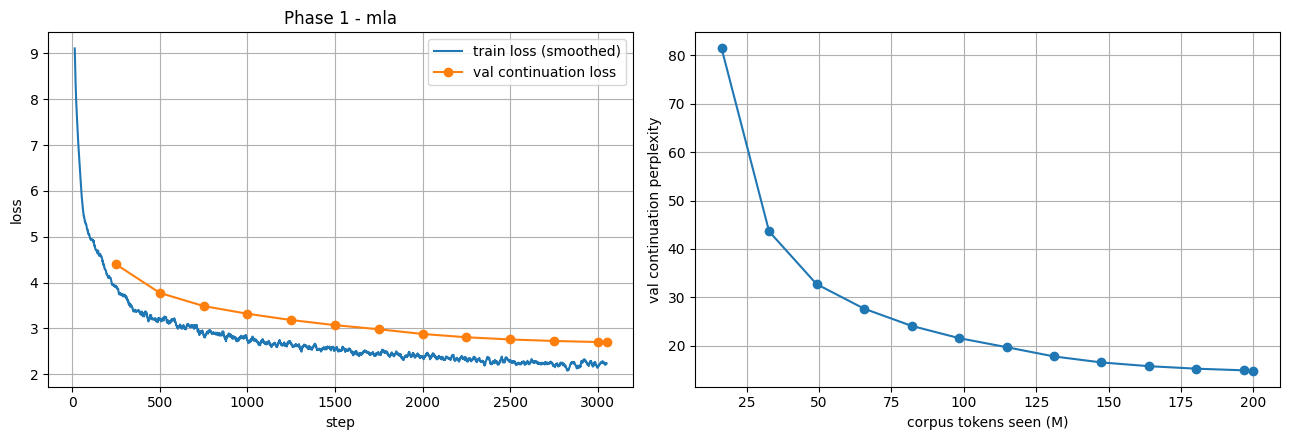

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
st, ls = zip(*train_log)
k = max(1, len(ls) // 200)
ax[0].plot(st[k - 1:], np.convolve(ls, np.ones(k) / k, mode="valid"), label="train loss (smoothed)")
ax[0].plot([h["step"] for h in history], [h["val_cont_loss"] for h in history], "o-", label="val continuation loss")
ax[0].set_xlabel("step"); ax[0].set_ylabel("loss"); ax[0].set_title(f"Phase 1 - {ARCH}"); ax[0].legend(); ax[0].grid(True)
ax[1].plot([h["tokens"] / 1e6 for h in history], [h["val_cont_ppl"] for h in history], "o-")
ax[1].set_xlabel("corpus tokens seen (M)"); ax[1].set_ylabel("val continuation perplexity"); ax[1].grid(True)
plt.tight_layout(); plt.savefig(WORK / "training_validation_loss.png", dpi=200); plt.show()

## 8. Generation utilities and checkpoint comparison (validation loss vs. generation quality)

In [12]:
# =================== generation utilities (shared by all architectures) ===================
SPECIAL_IDS = [EOS_ID, PAD_ID, BOS_ID]

def sample_next(lg, temperature, top_k, top_p):
    if temperature <= 0:
        return lg.argmax(-1)
    lg = lg / temperature
    if top_k and top_k > 0:
        kth = torch.topk(lg, min(top_k, lg.size(-1))).values[:, -1, None]
        lg = lg.masked_fill(lg < kth, -float("inf"))
    if top_p < 1.0:
        sl, si = torch.sort(lg, descending=True)
        probs = sl.softmax(-1)
        remove = (probs.cumsum(-1) - probs) > top_p
        sl = sl.masked_fill(remove, -float("inf"))
        lg = torch.full_like(lg, -float("inf")).scatter(1, si, sl)
    return torch.multinomial(lg.softmax(-1), 1).squeeze(1)

@torch.no_grad()
def generate_batch(prompt_ids, temperature, top_p, top_k, rep_penalty, max_new=MAX_NEW, min_words=TARGET_WORDS):
    """prompt_ids: (B, L) LongTensor, all the same length (no padding needed). Returns list of TARGET_WORDS-word strings."""
    model.eval()
    logits, cache = model.prefill(prompt_ids)
    B = prompt_ids.size(0)
    gen = prompt_ids.new_zeros((B, 0))
    for step in range(max_new):
        lg = logits.float()
        lg[:, SPECIAL_IDS] = -float("inf")                          # never stop early, never emit specials
        if rep_penalty != 1.0 and gen.size(1) > 0:                  # penalise only already-GENERATED tokens
            v = lg.gather(1, gen)
            lg.scatter_(1, gen, torch.where(v < 0, v * rep_penalty, v / rep_penalty))
        nxt = sample_next(lg, temperature, top_k, top_p)
        gen = torch.cat([gen, nxt[:, None]], dim=1)
        if (step + 1) % 32 == 0 and all(len(tokenizer.decode(g.tolist()).split()) >= min_words for g in gen):
            break
        logits, cache = model.decode_step(nxt, cache)
    return [" ".join(tokenizer.decode(g.tolist()).split()[:min_words]) for g in gen]

def generate_all(items, decode, batch_size=GEN_BS, verbose=True):
    """items: list of (id, prompt_text). Prompts are sorted by length and batched; inside a batch every prompt is
    left-truncated to the shortest one (loses only a handful of far-left tokens, removes the need for padding)."""
    maxp = model.max_prompt(MAX_NEW)
    enc = sorted(((i, tokenizer.encode(norm(t)).ids[-maxp:]) for i, t in items), key=lambda x: len(x[1]))
    out = {}
    for s in range(0, len(enc), batch_size):
        chunk = enc[s:s + batch_size]
        L = min(len(ids) for _, ids in chunk)
        x = torch.tensor([ids[-L:] for _, ids in chunk], device=device)
        with amp():
            texts = generate_batch(x, **decode)
        for (i, _), t in zip(chunk, texts):
            out[i] = t
        if verbose:
            print(f"generated {min(s + batch_size, len(enc))}/{len(enc)}")
    return out

In [13]:
# =================== checkpoint comparison: validation loss AND generation quality ===================
def lcs(a, b):
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0]
        for j, y in enumerate(b):
            cur.append(prev[j] + 1 if x == y else max(prev[j + 1], cur[j]))
        prev = cur
    return prev[-1]

import re
def rouge_l(pred, ref):
    p, r = re.findall(r"\w+", pred.lower()), re.findall(r"\w+", ref.lower())
    if not p or not r:
        return 0.0
    l = lcs(p, r)
    return 0.0 if l == 0 else 2 * l / (len(p) + len(r))

# local validation prompts built from val.bin (prompt ~650 tokens -> reference = next 128 words)
N_LOCAL, PR_TOK = 48, 650
_ids = val_mm.astype(np.int64)
_offs = np.linspace(0, len(_ids) - PR_TOK - 400, N_LOCAL).astype(int)
local_items, local_refs = [], {}
for k, o in enumerate(_offs):
    local_items.append((str(k), tokenizer.decode(_ids[o:o + PR_TOK].tolist())))
    local_refs[str(k)] = " ".join(tokenizer.decode(_ids[o + PR_TOK:o + PR_TOK + 400].tolist()).split()[:TARGET_WORDS])

# optional BERTScore (only as a LOCAL metric with a public model - never used in training/inference of the submission)
try:
    os.system(f"{sys.executable} -m pip -q install bert-score")
    from bert_score import BERTScorer
    scorer = BERTScorer(lang="en", device=device)
except Exception as e:
    scorer = None
    print("BERTScore unavailable, using ROUGE-L only:", type(e).__name__)

def local_eval(decode):
    outs = generate_all(local_items, decode, verbose=False)
    ids = [i for i, _ in local_items]
    cands, refs = [outs[i] for i in ids], [local_refs[i] for i in ids]
    r = float(np.mean([rouge_l(c, rf) for c, rf in zip(cands, refs)]))
    b = float(scorer.score(cands, refs)[2].mean()) if scorer is not None else float("nan")
    return r, b

def load_weights(path):
    model.load_state_dict(torch.load(path, map_location=device, weights_only=False)["model"])

rows = []
for p in sorted(WORK.glob("snap_step*.pt"), key=lambda q: int(q.stem.replace("snap_step", ""))) + [CKPT_BEST]:
    if not p.exists():
        continue
    load_weights(p)
    vc, _ = evaluate()
    r, b = local_eval(DECODE)
    rows.append((p.name, vc, math.exp(vc), r, b))
    print(f"{p.name:>16} | val cont loss {vc:.4f} | ppl {math.exp(vc):7.2f} | ROUGE-L {r:.4f} | BERTScore-F1 {b:.4f}")
json.dump(rows, open(WORK / "checkpoint_comparison.json", "w"))

# choose the checkpoint (default: best validation loss) and load it
CHOSEN = CKPT_BEST
load_weights(CHOSEN)
print("using", CHOSEN.name)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 19.3 kB/s eta 0:00:00


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


 snap_step762.pt | val cont loss 3.4706 | ppl   32.16 | ROUGE-L 0.2079 | BERTScore-F1 0.8207
snap_step1525.pt | val cont loss 3.0628 | ppl   21.39 | ROUGE-L 0.2240 | BERTScore-F1 0.8325
snap_step2287.pt | val cont loss 2.8021 | ppl   16.48 | ROUGE-L 0.2339 | BERTScore-F1 0.8337
snap_step3050.pt | val cont loss 2.6999 | ppl   14.88 | ROUGE-L 0.2445 | BERTScore-F1 0.8364
    ckpt_best.pt | val cont loss 2.6999 | ppl   14.88 | ROUGE-L 0.2304 | BERTScore-F1 0.8272
using ckpt_best.pt


## 9. Decoding sweep (temperature / top-p / repetition penalty)

In [14]:
# =================== decoding sweep (temperature / top-p / repetition penalty) ===================
SWEEP = [
    dict(temperature=0.0, top_p=1.0, top_k=0, rep_penalty=1.0),
    dict(temperature=0.0, top_p=1.0, top_k=0, rep_penalty=1.15),
    dict(temperature=0.2, top_p=0.9, top_k=0, rep_penalty=1.1),
    dict(temperature=0.4, top_p=0.9, top_k=0, rep_penalty=1.1),
    dict(temperature=0.7, top_p=0.95, top_k=0, rep_penalty=1.05),
]
sweep_rows = []
for d in SWEEP:
    r, b = local_eval(d)
    sweep_rows.append((d, r, b))
    print(d, f"-> ROUGE-L {r:.4f} | BERTScore-F1 {b:.4f}")
key = (lambda t: t[2]) if scorer is not None else (lambda t: t[1])
BEST_DECODE = max(sweep_rows, key=key)[0]
print("best decoding:", BEST_DECODE)
json.dump([(d, r, b) for d, r, b in sweep_rows], open(WORK / "decoding_sweep.json", "w"))

{'temperature': 0.0, 'top_p': 1.0, 'top_k': 0, 'rep_penalty': 1.0} -> ROUGE-L 0.2389 | BERTScore-F1 0.8210
{'temperature': 0.0, 'top_p': 1.0, 'top_k': 0, 'rep_penalty': 1.15} -> ROUGE-L 0.2457 | BERTScore-F1 0.8384
{'temperature': 0.2, 'top_p': 0.9, 'top_k': 0, 'rep_penalty': 1.1} -> ROUGE-L 0.2358 | BERTScore-F1 0.8333
{'temperature': 0.4, 'top_p': 0.9, 'top_k': 0, 'rep_penalty': 1.1} -> ROUGE-L 0.2463 | BERTScore-F1 0.8418
{'temperature': 0.7, 'top_p': 0.95, 'top_k': 0, 'rep_penalty': 1.05} -> ROUGE-L 0.2488 | BERTScore-F1 0.8413
best decoding: {'temperature': 0.4, 'top_p': 0.9, 'top_k': 0, 'rep_penalty': 1.1}


## 10. Generate 128-word continuations for the official test prompts -> `prediction.json` -> `submission.zip`

In [15]:
# =================== generate the 128-word continuations for the official test prompts ===================
items = [(str(k), v["text"]) for k, v in test_data.items()]
preds = generate_all(items, BEST_DECODE)
predictions = {k: {"text": preds[k]} for k, _ in items}

PREDICTION_PATH = WORK / "prediction.json"
SUBMISSION_ZIP = WORK / "submission.zip"
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(PREDICTION_PATH, arcname="prediction.json")          # must be at the zip root

# ---- format checks (Codabench checks IDs explicitly) ----
assert set(predictions) == {str(k) for k in test_data}, "IDs differ from the official test IDs"
wc = [len(v["text"].split()) for v in predictions.values()]
print(f"{len(predictions)} predictions | words per text: min {min(wc)}, max {max(wc)} | empty: {sum(w == 0 for w in wc)}")
print("submission:", SUBMISSION_ZIP)
k0 = items[0][0]
print("\nPROMPT (tail):", " ".join(test_data[k0]["text"].split()[-40:]))
print("CONTINUATION :", predictions[k0]["text"][:400])

generated 16/1000
generated 32/1000
generated 48/1000
generated 64/1000
generated 80/1000
generated 96/1000
generated 112/1000
generated 128/1000
generated 144/1000
generated 160/1000
generated 176/1000
generated 192/1000
generated 208/1000
generated 224/1000
generated 240/1000
generated 256/1000
generated 272/1000
generated 288/1000
generated 304/1000
generated 320/1000
generated 336/1000
generated 352/1000
generated 368/1000
generated 384/1000
generated 400/1000
generated 416/1000
generated 432/1000
generated 448/1000
generated 464/1000
generated 480/1000
generated 496/1000
generated 512/1000
generated 528/1000
generated 544/1000
generated 560/1000
generated 576/1000
generated 592/1000
generated 608/1000
generated 624/1000
generated 640/1000
generated 656/1000
generated 672/1000
generated 688/1000
generated 704/1000
generated 720/1000
generated 736/1000
generated 752/1000
generated 768/1000
generated 784/1000
generated 800/1000
generated 816/1000
generated 832/1000
generated 848/1000

## 11. Export for Phases 2-7

In [16]:
# =================== export everything Phases 2-7 need (weights + config + model code + tokenizer) ===================
EXPORT_DIR = WORK / f"export_{ARCH}"
EXPORT_DIR.mkdir(exist_ok=True)
torch.save(model.state_dict(), EXPORT_DIR / "model.pt")
json.dump({"arch": ARCH, "cfg": asdict(cfg), "params": n_params}, open(EXPORT_DIR / "config.json", "w"), indent=2)
shutil.copy("legal_arch.py", EXPORT_DIR / "legal_arch.py")
shutil.copy(DATA_DIR / "tokenizer.json", EXPORT_DIR / "tokenizer.json")
print("exported to", EXPORT_DIR)
print("Later phases:  import legal_arch as LA; cfg = LA.ArchConfig(**config['cfg']); m = LA.build_model(cfg); m.load_state_dict(torch.load('model.pt'))")

exported to /kaggle/working/cs781_phase1_mla/export_mla
Later phases:  import legal_arch as LA; cfg = LA.ArchConfig(**config['cfg']); m = LA.build_model(cfg); m.load_state_dict(torch.load('model.pt'))
